# CDnet2014 · Final Integrated Research Workflow

**Satu notebook untuk keseluruhan paket riset.** Tabel dan angka sebelumnya sudah tersedia; *audit* tidak perlu dataset asli. Kajian temporal, resolusi, dan model eksternal **tidak berjalan otomatis**. Perlu video asli dan akan diberi label **EXPLORATORY**. Hasil utama V3 tidak akan ditimpa.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
from IPython.display import display, Markdown
import pandas as pd

# Jika notebook dijalankan dari folder lain, isi path absolut proyek di bawah.
PROJECT_DIR = os.environ.get('CDNET_PROJECT_DIR', '')
if PROJECT_DIR:
    ROOT = Path(PROJECT_DIR).expanduser().resolve()
else:
    cwd=Path.cwd()
    candidates=[cwd, *cwd.parents, cwd/'CDnet_Research_Final', cwd/'cdnet_paper_v3']
    ROOT=next((p for p in candidates if (p/'paper_protocol.py').is_file()), None)
if ROOT is None or not (ROOT/'paper_protocol.py').exists():
    raise FileNotFoundError('Root proyek tidak ditemukan. Isi CDNET_PROJECT_DIR dengan lokasi folder CDnet_Research_Final.')
sys.path.insert(0,str(ROOT))
print('Project:',ROOT)
print('Python kernel:',sys.executable)

Project: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\CDnet2014_FINAL_Research_Paper_Package\CDnet_Research_Final
Python kernel: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\.venv\Scripts\python.exe


## 1. Audit dan rangkum angka asli (tanpa rerun video)

In [2]:
from final_studies.audit_final import run as audit_run
from final_studies.compile_results import build
status=audit_run(ROOT)
assert status['technical_audit_passed'], status['issues']
build(ROOT)
display(Markdown('**Audit integritas: LULUS**. Perhitungan ulang F1 dari hitungan TP/FP/FN konsisten dengan ringkasan yang diarsipkan.'))
print(json.dumps(status['recomputed_category_mean_f1'],indent=2))

**Audit integritas: LULUS**. Perhitungan ulang F1 dari hitungan TP/FP/FN konsisten dengan ringkasan yang diarsipkan.

{
  "B1t": 0.229954,
  "B2t": 0.471391,
  "B3t": 0.48322,
  "B4t": 0.202505
}


## 2. Tabel dan gambar hasil gabungan 11 kategori — dua fase terpisah

,phase,category,Farneback,Frame Difference,KNN,MOG2
0,development_test_inspected,badWeather,0.592,0.329,0.502,0.450
1,development_test_inspected,baseline,0.514,0.795,0.840,0.815
2,development_test_inspected,dynamicBackground,0.310,0.136,0.508,0.523
3,development_test_inspected,nightVideos,0.355,0.405,0.377,0.368
4,development_test_inspected,shadow,0.528,0.574,0.702,0.705
5,later_category_disjoint_test,PTZ,0.204,0.316,0.203,0.215
6,later_category_disjoint_test,cameraJitter,0.128,0.154,0.709,0.667
7,later_category_disjoint_test,intermittentObjectMotion,0.171,0.259,0.372,0.317
8,later_category_disjoint_test,lowFramerate,0.220,0.279,0.474,0.486
9,later_category_disjoint_test,thermal,0.394,0.339,0.573,0.517


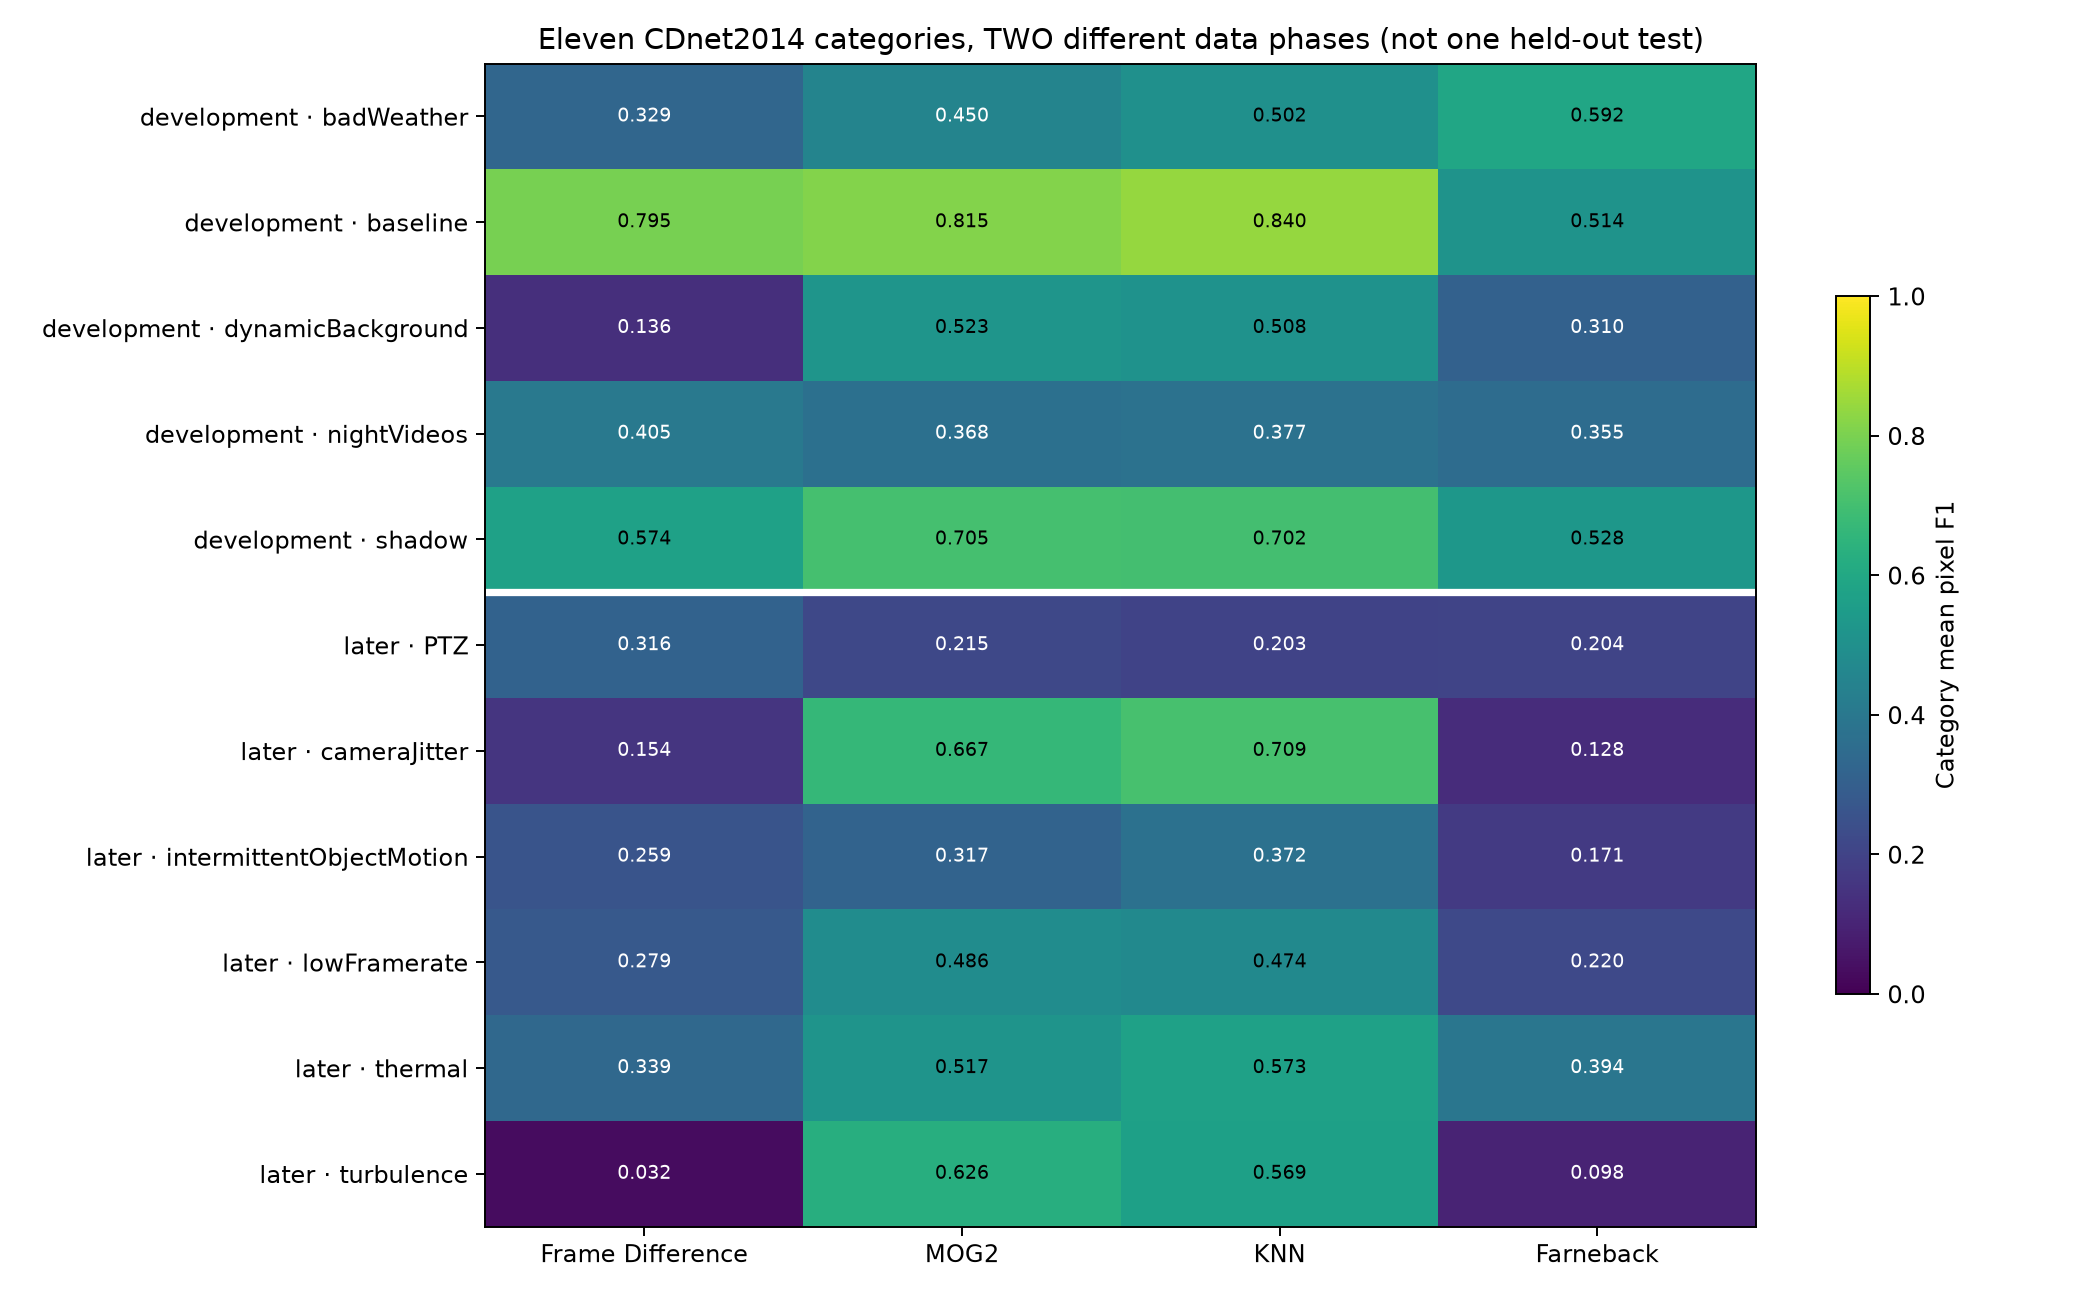

In [3]:
table = pd.read_csv(ROOT/'paper/COMBINED_F1_11_CATEGORIES_PHASE_LABELED.csv')
display(table.round(3))
from IPython.display import Image
display(Image(filename=str(ROOT/'paper/FIG_ALL_11_CATEGORIES_PHASED.png'),width=850))

## 3. Hasil hipotesis dan default-vs-tuned dari evaluasi yang sudah dibekukan

In [4]:
holdout = ROOT/'working/results-v3-confirmatory'
display(pd.read_csv(holdout/'table_main.csv'))
display(pd.read_csv(holdout/'table_hypotheses.csv'))
display(pd.read_csv(holdout/'table_default_vs_tuned.csv'))

,Algoritma,P,R,F [CI95],PWC,MCC frame,F1 box@0.5,IoU (TP),FPS (median)
0,B1 Frame Difference (tuned),0.350,0.627,"0.230 [0.172, 0.287]",15.13,"0.199 [0.137, 0.266]",0.097,0.629,2546
1,B2 MOG2 (tuned),0.672,0.453,"0.471 [0.405, 0.545]",3.50,"0.373 [0.297, 0.450]",0.272,0.720,598
2,B3 KNN (tuned),0.666,0.496,"0.483 [0.404, 0.562]",3.79,"0.387 [0.310, 0.470]",0.281,0.732,403
3,B4 Farneback (tuned),0.231,0.555,"0.203 [0.151, 0.253]",17.55,"0.182 [0.113, 0.253]",0.061,0.624,86
4,Selalu foreground (trivial),0.038,1.000,"0.070 [0.049, 0.095]",96.19,0,-,-,-


,Hipotesis,Keluarga,Metrik,n kategori,Efek [CI95],p satu sisi kategori,p dua sisi (deskriptif),p Holm,Keputusan statistik
0,H1: MOG2 > Frame Difference (F piksel),algoritma,F piksel,6,"0.241 [0.196, 0.285]",0.047,0.094,0.062,tidak signifikan
1,H2: KNN > Frame Difference (F piksel),algoritma,F piksel,6,"0.253 [0.201, 0.304]",0.031,0.062,0.062,tidak signifikan
2,H3: Blur menurunkan FPR Frame Difference,preprocessing,FPR piksel,6,"-0.028 [-0.036, -0.020]",0.016,0.031,0.031,arah didukung
3,H4: Morphology meningkatkan F1 Frame Difference,preprocessing,F piksel,6,"0.041 [0.029, 0.057]",0.016,0.031,0.031,arah didukung


,Algoritma,Parameter,Default,Tuned,F piksel default (test),F piksel tuned (test),F piksel default (semua seq)
0,B1 Frame Difference,fixed_thr,25,5,0.228,0.230,0.228
1,B2 MOG2,var_threshold,16,25,0.459,0.471,0.459
2,B3 KNN,dist2_threshold,400,600,0.489,0.483,0.489
3,B4 Farneback,flow_thr,1,1,0.203,0.203,0.203


## 4. Opsional — analisis temporal pada video ASLI

Aktifkan `RUN_TEMPORAL=True` dan set `DATASET_DIR` secara eksplisit. Memproses frame dari awal untuk warm-up; jangan jalankan penuh tanpa mempertimbangkan waktu CPU. Hasil berlabel **post-hoc exploratory**.

In [5]:
DATASET_DIR = r'D:\Datasets\CDnet2014'  # SESUAIKAN
RUN_TEMPORAL = False
if RUN_TEMPORAL:
    assert Path(DATASET_DIR).is_dir(), f'Dataset not found: {DATASET_DIR}'
    subprocess.run([sys.executable,'run_final.py','temporal','--dataset',DATASET_DIR],cwd=ROOT,check=True)
else:
    print('Temporal study disabled (existing results retained).')

Temporal study disabled (existing results retained).


## 5. Opsional — sensitivitas resolusi (320 / 640 / native)

In [6]:
RUN_RESOLUTION = False
if RUN_RESOLUTION:
    assert Path(DATASET_DIR).is_dir(), f'Dataset not found: {DATASET_DIR}'
    subprocess.run([sys.executable,'run_final.py','resolution','--dataset',DATASET_DIR,
                    '--widths','320','640','native'],cwd=ROOT,check=True)
else:
    print('Resolution study disabled; no resolution outcomes claimed.')

Resolution study disabled; no resolution outcomes claimed.


## 6. Opsional — nilai mask model modern eksternal secara fair

In [7]:
RUN_EXTERNAL_MODEL = False
PREDICTIONS_DIR = r'D:\ModelPredictions'
MODEL_NAME = 'model_name'
if RUN_EXTERNAL_MODEL:
    subprocess.run([sys.executable,'run_final.py','external','--dataset',DATASET_DIR,
                    '--predictions',PREDICTIONS_DIR,'--model',MODEL_NAME],cwd=ROOT,check=True)
else:
    print('No modern model scores available or claimed.')

No modern model scores available or claimed.


## 7. Manuskrip, bibliografi dan submission gate

In [8]:
print('Manuscript Word:', ROOT/'paper/MANUSCRIPT_MASTER.docx')
print('Manuscript Markdown:',ROOT/'paper/MANUSCRIPT_MASTER.md')
print('Bibliography:',ROOT/'paper/REFERENCES.bib')
print('Submission gate:',ROOT/'SUBMISSION_GATE.md')
display(Markdown('**Penting:** Walaupun paket ini terintegrasi, SINTA 2 bukan jaminan diterima. Lengkapi bukti preregistrasi, analisis berbasis raw video jika mengklaim mekanisme, jurnal tujuan, dan persetujuan penulis.'))

Manuscript Word: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\CDnet2014_FINAL_Research_Paper_Package\CDnet_Research_Final\paper\MANUSCRIPT_MASTER.docx
Manuscript Markdown: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\CDnet2014_FINAL_Research_Paper_Package\CDnet_Research_Final\paper\MANUSCRIPT_MASTER.md
Bibliography: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\CDnet2014_FINAL_Research_Paper_Package\CDnet_Research_Final\paper\REFERENCES.bib
Submission gate: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\CDnet2014_FINAL_Research_Paper_Package\CDnet_Research_Final\SUBMISSION_GATE.md


**Penting:** Walaupun paket ini terintegrasi, SINTA 2 bukan jaminan diterima. Lengkapi bukti preregistrasi, analisis berbasis raw video jika mengklaim mekanisme, jurnal tujuan, dan persetujuan penulis.